<a href="https://colab.research.google.com/github/tejsvinimeshram/Practical/blob/main/EE524_task9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
#print(np._version)


In [ ]:
class Layer:
  def __init__(self):
    self.input = None
    self.output = None
  def forward(self, input):
    pass
  def backward(self, output_gradient, learning_rate):
    pass

In [ ]:
class Dense(Layer):
  def __init__(self, input_size, output_size):
    self.weights = np.random.randn(output_size, input_size)
    self.bias = np.random.randn(output_size, 1)

  def forward(self, input):
    self.input = input
    return np.dot(self.weights, self.input) + self.bias

  def backward(self, output_gradient, learning_rate):
    weights_gradient = np.dot(output_gradient, self.input.T)
    input_gradient = np.dot(self.weights.T, output_gradient)
    self.weights -= learning_rate * weights_gradient
    self.bias -= learning_rate * output_gradient
    return input_gradient

In [ ]:
def mse(y_true, y_pred):
  return np.mean(np.power(y_true-y_pred, 2));
def mse_prime(y_true, y_pred):
  return 2*(y_pred-y_true)/np.size(y_true);

In [ ]:
class Activation(Layer):
  def __init__(self, activation, activation_prime):
    self.activation = activation
    self.activation_prime = activation_prime
  def forward(self, input):
    self.input = input
    return self.activation(self.input)
  def backward(self, output_gradient, learning_rate):
    return np.multiply(output_gradient, self.activation_prime(self.input))

In [ ]:
class Tanh(Activation):
  def __init__(self):
    def tanh(x):
      return np.tanh(x)
    def tanh_prime(x):
      return 1 - np.tanh(x)**2
    super().__init__(tanh, tanh_prime)

class Sigmoid(Activation):
  def __init__(self):
    def sigmoid(x):
      return 1 / (1 + np.exp(-x))
    def sigmoid_prime(x):
      s = sigmoid(x)
      return s * (1 - s)
    super().__init__(sigmoid, sigmoid_prime)

In [ ]:
import math

In [ ]:
class Linear(Activation):
  def __init__(self):
    def linear(x):
      return x
    def linear_prime(x):
      return 1
    super().__init__(linear, linear_prime)

In [ ]:
x=np.array([[0,0,1],[0,1,1],[1,0,1],[1,1,1]])
y=np.array([[0],[1],[1],[0]])
network=[Dense(3,4),Linear()]
epochs=10000
learning_rate=0.1
errorlist=[]
for e in range(epochs):
  error=0
  for x_,y_ in zip(x,y):
    # Reshape input and target to be 2D column vectors
    output=x_.reshape(-1, 1)
    target=y_.reshape(-1, 1)
    for layer in network:
      output=layer.forward(output)
    error+=mse(target,output)
    grad=mse_prime(target,output)
    for layer in reversed(network):
      grad=layer.backward(grad,learning_rate)
  if (e + 1) % 1000 == 0:
    print(f"{e+1}/{epochs},error={error/len(x)}")
  errorlist.append(error)

1000/10000,error=0.5102040816326532
2000/10000,error=0.5102040816326532
3000/10000,error=0.5102040816326532
4000/10000,error=0.5102040816326532
5000/10000,error=0.5102040816326532
6000/10000,error=0.5102040816326532
7000/10000,error=0.5102040816326532
8000/10000,error=0.5102040816326532
9000/10000,error=0.5102040816326532
10000/10000,error=0.5102040816326532


In [ ]:
X1=[0.15]
for x in X1:
  output=x
  for layer in network:
    output=layer.forward(output)
  print(output)

[[-0.45388408 -0.41102694 -0.22401575]
 [-0.43159786 -0.38874072 -0.20507247]
 [ 1.1874871   1.23034424  1.17114975]
 [ 0.87510853  0.91796567  0.90562797]]


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
# Access weights and biases directly from the Dense layer in the network
dense_layer = network[0]

# Get the weight and bias arrays
weights = dense_layer.weights
biases = dense_layer.bias

# Safely extract a single element if needed
w = weights[0][0]
b = biases[0][0]

print("Weight element w:", w)
print("Bias element b:", b)

Weight element w: -0.4285714285714285
Bias element b: -0.389598366022892


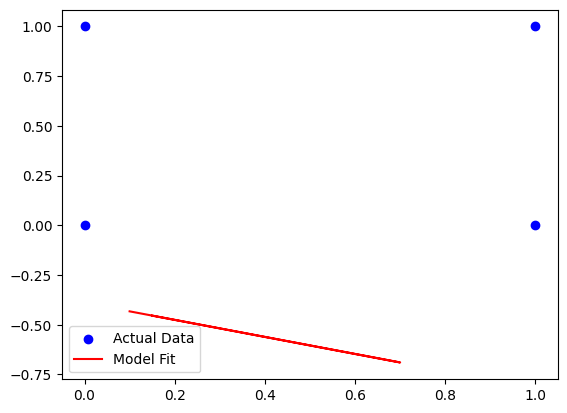

In [ ]:
# Re-defining or referencing the dataset with unique names to avoid variable conflicts
x_data = np.array([[0,0,1],[0,1,1],[1,0,1],[1,1,1]])
y_data = np.array([[0],[1],[1],[0]])

# Plot the first feature of our inputs against the target labels
plt.scatter(x_data[:, 0], y_data, color='blue', label='Actual Data')

# Plot the fit line
x1 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.15]
y1 = [(w * i + b) for i in x1]
plt.plot(x1, y1, color='r', label='Model Fit')
plt.legend()
plt.show()